# Tutorial 03b

This notebook fits support vector machines to the same trip data used in Tutorial 03a. The binary target is `active`: walking or cycling versus all other travel modes.

Two choices are central: `C` controls the trade-off between margin width and classification errors, while the kernel determines the shape of the decision boundary. The following sections examine and visualise both.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `mode_choice.csv`.
- **On your own computer.** Open this file from the `03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)` folder, so `mode_choice.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, and scikit-learn fits the models.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## The trips

`mode_choice.csv` is the same file as in tutorial 03a, from the Victorian Integrated Survey of Travel and Activity (VISTA) 2024–2025, Department of Transport and Planning, Victoria, CC BY 4.0.

`active` is 1 for walk or bike. The rows were shuffled once. Car is still the largest mode, so accuracy on the four modes would look strong even when bike is missed. This notebook scores the active class.


In [4]:
trips = pd.read_csv("mode_choice.csv")
print("rows", len(trips))
print("active share", round(float(trips["active"].mean()), 3))


rows 17680
active share 0.183


## Train and test

The first 75% of the rows are the training set. The last 25% are the test set. Fit only on the training rows.

Distance, time, and the counts stay in their original units, as in the logistic regression notebook. `get_dummies` turns each category into columns of zeros and ones. The test rows use the same columns.


In [5]:
n_train = int(len(trips) * 0.75)
train = trips.iloc[:n_train].copy()
test = trips.iloc[n_train:].copy()
print("train", len(train), "rows")
print("test ", len(test), "rows")

num = ["distance_km", "travel_min", "start_hour", "hh_vehicles", "hh_bikes"]
cat = ["purpose", "day_type", "age_group", "sex", "car_licence", "employed"]
train_ready = pd.concat([
    train[num],
    pd.get_dummies(train[cat], dtype=int),
], axis=1)
test_ready = pd.concat([
    test[num],
    pd.get_dummies(test[cat], dtype=int),
], axis=1)
test_ready = test_ready.reindex(columns=train_ready.columns, fill_value=0)

print("columns", train_ready.shape[1])


train 13260 rows
test  4420 rows
columns 44



## Soft margin and C

An SVM searches for a separating margin between the two classes. Some observations may fall inside the margin or on the wrong side of the boundary; `C` controls the penalty assigned to such observations.

A large `C` penalises classification errors more strongly and therefore tends to produce a narrower margin. A small `C` tolerates more violations and permits a wider margin.

The trips that sit on the gap, or inside it, are the support vectors. A larger `C` usually leaves fewer of them. The two fits below use a linear kernel, so the boundary is a straight cut.

The ROC curve reads the decision score in the same way tutorial 03a read a probability. A higher score means the trip looks more active. The hard label switches at a score of 0. AUC is the area under the curve, and it is printed next to the F1.


    C  test F1  test AUC  support vectors
0.001    0.757     0.965             3623
1.000    0.831     0.968             2461


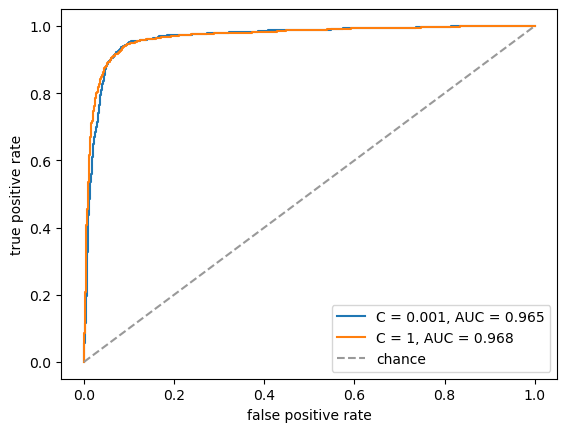

In [6]:

from sklearn.svm import SVC
from sklearn.metrics import f1_score, roc_curve, roc_auc_score

rows = []
for C in [0.001, 1]:
    model = SVC(kernel="linear", C=C)
    model.fit(train_ready, train["active"])
    score = model.decision_function(test_ready)
    pred = (score > 0).astype(int)
    auc = roc_auc_score(test["active"], score)
    rows.append({
        "C": C,
        "test F1": f1_score(test["active"], pred),
        "test AUC": auc,
        "support vectors": int(model.n_support_.sum()),
    })
    fpr, tpr, _ = roc_curve(test["active"], score)
    plt.plot(fpr, tpr, label=f"C = {C}, AUC = {auc:.3f}")

linear_table = pd.DataFrame(rows)
print(linear_table.round(3).to_string(index=False))
plt.plot([0, 1], [0, 1], color="0.6", linestyle="--", label="chance")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.show()


## The margin, drawn in two columns

A plot has only two axes, so this cell uses distance and travel time, in the original units. This is a separate fit from the model above. The same two values of `C` are used.

The solid line is the decision boundary. The dashed lines are the two edges of the margin. A larger `C` pulls the dashed lines closer together.


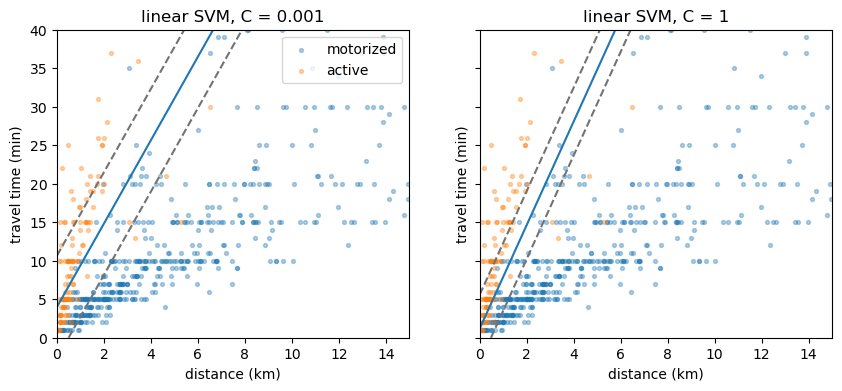

In [7]:
two = ["distance_km", "travel_min"]
X_two = train[two]

distance_axis = np.linspace(0, 15, 120)
time_axis = np.linspace(0, 40, 120)
distance_grid, time_grid = np.meshgrid(distance_axis, time_axis)
mesh = pd.DataFrame({
    "distance_km": distance_grid.ravel(),
    "travel_min": time_grid.ravel(),
})

window = train[(train["distance_km"] <= 15) & (train["travel_min"] <= 40)]
shown = window.sample(600, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, C in zip(axes, [0.001, 1]):
    picture = SVC(kernel="linear", C=C)
    picture.fit(X_two, train["active"])
    score = picture.decision_function(mesh[two]).reshape(distance_grid.shape)
    ax.contour(
        distance_grid, time_grid, score,
        levels=[-1, 0, 1],
        colors=["0.45", "C0", "0.45"],
        linestyles=["--", "-", "--"],
    )
    ax.scatter(
        shown.loc[shown["active"] == 0, "distance_km"],
        shown.loc[shown["active"] == 0, "travel_min"],
        s=8, alpha=0.35, label="motorized",
    )
    ax.scatter(
        shown.loc[shown["active"] == 1, "distance_km"],
        shown.loc[shown["active"] == 1, "travel_min"],
        s=8, alpha=0.35, label="active",
    )
    ax.set_title(f"linear SVM, C = {C}")
    ax.set_xlabel("distance (km)")
    ax.set_ylabel("travel time (min)")
axes[0].legend(loc="upper right")
plt.show()



## Linear kernel and RBF kernel

A linear kernel produces a flat decision boundary, whereas the radial basis function (RBF) kernel can produce a nonlinear boundary. The lecture expresses the RBF kernel using a width parameter $s$:

$$
K(\mathbf{x}, \mathbf{x}') = \exp\left(-\frac{||\mathbf{x}-\mathbf{x}'||^2}{2s^2}\right)
$$

scikit-learn writes the same kernel with `gamma`:

$$
K(\mathbf{x}, \mathbf{x}') = \exp\left(-\gamma ||\mathbf{x}-\mathbf{x}'||^2\right)
$$

The two parameters are the same width, written differently:

$$
\gamma = \frac{1}{2s^2}
$$

A large `gamma` is a small $s$. Each training trip then affects only nearby trips. A small `gamma` is a large $s$, so one trip still affects trips far away.

On the earlier margin slides, the symbol $\gamma$ is the gap, $\gamma = 1/||\mathbf{w}||$. The `gamma` in `SVC` is the kernel width above.

The cell fits both kernels at `C = 1`. The RBF fit uses scikit-learn's default `gamma`. That default is one setting, not a tuned one. Both scores go on one ROC curve.


kernel  C  test F1  test AUC  support vectors
linear  1    0.831     0.968             2461
   rbf  1    0.823     0.972             3052


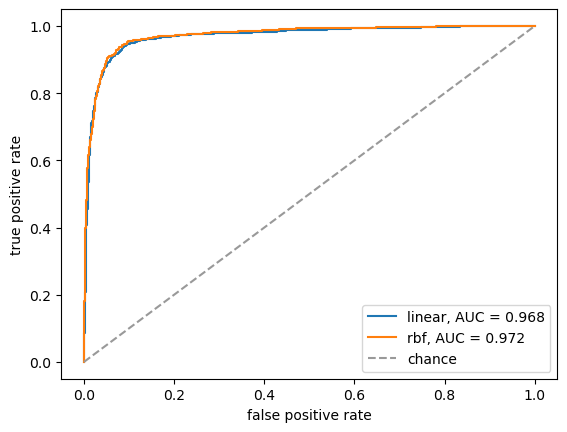

In [8]:

kernel_rows = []
for kernel in ["linear", "rbf"]:
    model = SVC(kernel=kernel, C=1)
    model.fit(train_ready, train["active"])
    score = model.decision_function(test_ready)
    pred = (score > 0).astype(int)
    auc = roc_auc_score(test["active"], score)
    kernel_rows.append({
        "kernel": kernel,
        "C": 1,
        "test F1": f1_score(test["active"], pred),
        "test AUC": auc,
        "support vectors": int(model.n_support_.sum()),
    })
    fpr, tpr, _ = roc_curve(test["active"], score)
    plt.plot(fpr, tpr, label=f"{kernel}, AUC = {auc:.3f}")

print(pd.DataFrame(kernel_rows).round(3).to_string(index=False))
plt.plot([0, 1], [0, 1], color="0.6", linestyle="--", label="chance")
plt.xlabel("false positive rate")
plt.ylabel("true positive rate")
plt.legend()
plt.show()

# At this one value of C, read which kernel has the higher test F1 and the higher AUC.
# Changing gamma can move the RBF result. That search is the exercise.



## What moves the score

Hold all other features at representative training values and vary one feature at a time. Tutorial 03a examined predicted probabilities; an SVM instead produces a decision score, with scores above 0 classified as active.

A linear kernel has one weight per column, so the score falls in a straight line as distance grows. An RBF kernel has no single weight. With the default `gamma` the kernel is very wide on these raw columns, and the score still falls almost like a line. `gamma = 0.1` is narrower. After a few kilometres the score flattens, because a long trip is simply far from the short walking and cycling trips.


distance_km   -1.464
travel_min     0.205
start_hour    -0.036
hh_vehicles   -0.279
hh_bikes       0.117
dtype: float64


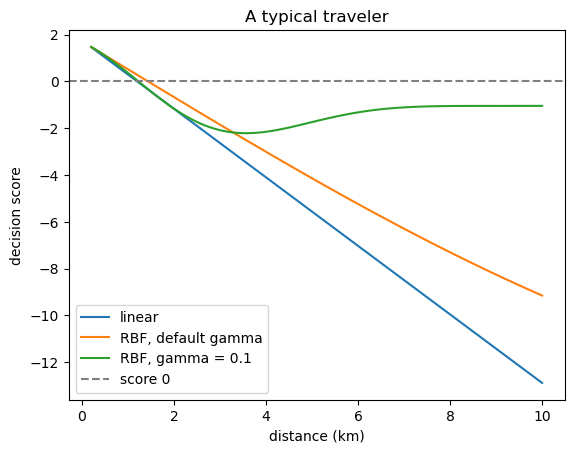

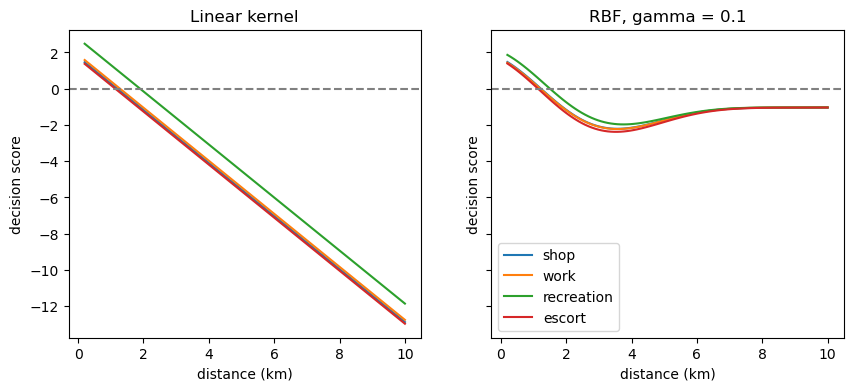

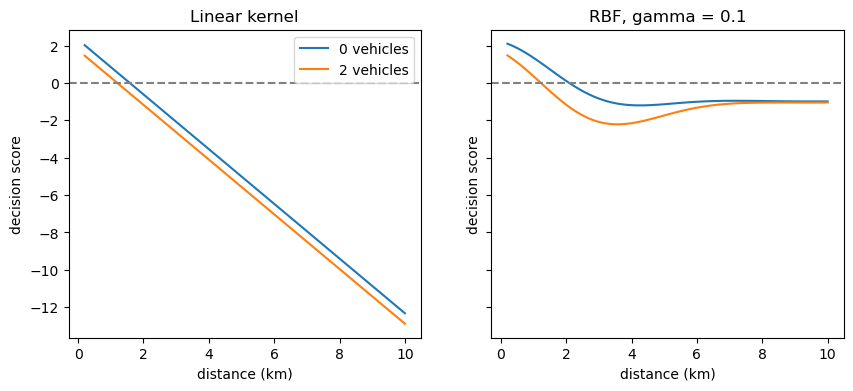

In [9]:

linear_svm = SVC(kernel="linear", C=1)
linear_svm.fit(train_ready, train["active"])
rbf_wide = SVC(kernel="rbf", C=1)
rbf_wide.fit(train_ready, train["active"])
rbf_narrow = SVC(kernel="rbf", C=1, gamma=0.1)
rbf_narrow.fit(train_ready, train["active"])
fitted = [
    ("linear", linear_svm),
    ("RBF, default gamma", rbf_wide),
    ("RBF, gamma = 0.1", rbf_narrow),
]
print(pd.Series(linear_svm.coef_[0], index=train_ready.columns)[num].round(3))

grid = np.linspace(0.2, 10, 100)
curve = pd.DataFrame({
    "distance_km": grid,
    "travel_min": train["travel_min"].median(),
    "start_hour": train["start_hour"].median(),
    "hh_vehicles": train["hh_vehicles"].median(),
    "hh_bikes": train["hh_bikes"].median(),
    "purpose": train["purpose"].mode().iloc[0],
    "day_type": train["day_type"].mode().iloc[0],
    "age_group": train["age_group"].mode().iloc[0],
    "sex": train["sex"].mode().iloc[0],
    "car_licence": train["car_licence"].mode().iloc[0],
    "employed": train["employed"].mode().iloc[0],
})
curve_ready = pd.concat([
    curve[num],
    pd.get_dummies(curve[cat], dtype=int),
], axis=1)
curve_ready = curve_ready.reindex(columns=train_ready.columns, fill_value=0)

for name, model in fitted:
    plt.plot(grid, model.decision_function(curve_ready), label=name)
plt.axhline(0, color="0.5", linestyle="--", label="score 0")
plt.xlabel("distance (km)")
plt.ylabel("decision score")
plt.title("A typical traveler")
plt.legend()
plt.show()

shop = curve.copy()
shop["purpose"] = "shop"
work = curve.copy()
work["purpose"] = "work"
recreation = curve.copy()
recreation["purpose"] = "recreation"
escort = curve.copy()
escort["purpose"] = "escort"
by_purpose = pd.concat([shop, work, recreation, escort], ignore_index=True)
by_purpose_ready = pd.concat([
    by_purpose[num],
    pd.get_dummies(by_purpose[cat], dtype=int),
], axis=1)
by_purpose_ready = by_purpose_ready.reindex(columns=train_ready.columns, fill_value=0)
n = len(grid)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, model in zip(axes, [linear_svm, rbf_narrow]):
    scores = model.decision_function(by_purpose_ready)
    ax.plot(grid, scores[0:n], label="shop")
    ax.plot(grid, scores[n:2 * n], label="work")
    ax.plot(grid, scores[2 * n:3 * n], label="recreation")
    ax.plot(grid, scores[3 * n:4 * n], label="escort")
    ax.axhline(0, color="0.5", linestyle="--")
    ax.set_xlabel("distance (km)")
    ax.set_ylabel("decision score")
axes[0].set_title("Linear kernel")
axes[1].set_title("RBF, gamma = 0.1")
axes[1].legend()
plt.show()

no_car = curve.copy()
no_car["hh_vehicles"] = 0
two_cars = curve.copy()
two_cars["hh_vehicles"] = 2
by_vehicles = pd.concat([no_car, two_cars], ignore_index=True)
by_vehicles_ready = pd.concat([
    by_vehicles[num],
    pd.get_dummies(by_vehicles[cat], dtype=int),
], axis=1)
by_vehicles_ready = by_vehicles_ready.reindex(columns=train_ready.columns, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, model in zip(axes, [linear_svm, rbf_narrow]):
    scores = model.decision_function(by_vehicles_ready)
    ax.plot(grid, scores[0:n], label="0 vehicles")
    ax.plot(grid, scores[n:2 * n], label="2 vehicles")
    ax.axhline(0, color="0.5", linestyle="--")
    ax.set_xlabel("distance (km)")
    ax.set_ylabel("decision score")
axes[0].set_title("Linear kernel")
axes[1].set_title("RBF, gamma = 0.1")
axes[0].legend()
plt.show()

# The printed numbers are the linear kernel's weight on each numeric column.
# Distance has a negative weight, so a longer trip lowers the score in a straight line.
# The narrow RBF has no single weight. Its score drops and then flattens.
